# Planners-07-OR-Tools-Python - Programmation par Contraintes

**Navigation** : [Index](../../README.md) | [<< Domaines](../02-Classical/Planners-06-Domains-Python.ipynb) | [Temporel >>](Planners-08-Temporal-Python.ipynb)

## OR-Tools pour la Planification

Ce notebook introduit **Google OR-Tools**, une suite d'optimisation open-source qui offre une approche complémentaire a la planification PDDL classique. Plutot que de chercher dans un espace d'états, OR-Tools utilise la **programmation par contraintes (CP-SAT)** pour résoudre des problèmes de planification.

### Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :
1. **Comprendre** le paradigme de programmation par contraintes (CP)
2. **Utiliser** OR-Tools CP-SAT pour des problèmes de planification
3. **Modéliser** des problèmes d'ordonnancement (job-shop scheduling)
4. **Résoudre** des problèmes de tournees de véhicules (VRP)
5. **Comparer** CP vs PDDL : forces et faiblesses de chaque approche

### Prerequis
- Avoir suivi [Planners-02-PDDL-Basics-Python](../01-Foundation/Planners-02-PDDL-Basics-Python.ipynb)
- Connaissance de base en Python
- Notions d'optimisation combinatoire

### Durée estimee : 45 minutes

***

## 1. Introduction a la Programmation par Contraintes

La **Programmation par Contraintes (CP)** est un paradigme différent de la planification classique basee sur PDDL.

### 1.1 CP vs PDDL : Deux paradigmes

| Aspect | PDDL (Planification) | CP (Contraintes) |
|--------|---------------------|------------------|
| **Modèle** | États + Actions | Variables + Contraintes |
| **Resolution** | Recherche dans l'espace d'états | Propagation + Recherche |
| **Objectif** | Sequence d'actions | Affectation de variables |
| **Optimalité** | Plan le plus court | Minimisation/Maximisation |
| **Problèmes types** | Blocks World, Logistics | Scheduling, Routing, Sudoku |

### 1.2 Quand utiliser CP vs PDDL ?

**Utiliser PDDL quand** :
- Le problème implique des actions avec préconditions/effets
- L'ordre des actions est crucial
- On cherche un plan (sequence d'actions)

**Utiliser CP quand** :
- Le problème est essentiellement combinatoire
- On optimise une fonction objectif (temps, coût, ressources)
- Les contraintes sont plus naturelles que les actions
- Le problème est statique (pas de "sequence d'actions")

### 1.3 Éléments du modèle CP

Un problème CP se définit par :

1. **Variables de decision** : $x_1, x_2, \ldots, x_n$ avec domaines $D_1, D_2, \ldots, D_n$
2. **Contraintes** : Relations entre variables ($x_1 + x_2 \leq 10$, $x_1 \neq x_2$)
3. **Fonction objectif** : Minimiser ou maximiser $f(x_1, \ldots, x_n)$

**Exemple** : Scheduling
- Variables : $start_i$ = temps de debut de la tâche $i$
- Contraintes : $start_i + duration_i \leq start_j$ (précédence)
- Objectif : Minimiser $\max_i(start_i + duration_i)$ (makespan)

***

## 2. OR-Tools CP-SAT : Les bases

**CP-SAT** est le solveur de contraintes le plus performant d'OR-Tools. Il combine :
- Propagation de contraintes
- Recherche arborescente
- Resolution SAT moderne (CDCL)
- Optimisation par recherche lineaire

In [1]:
# Imports et verification de l'environnement
import sys
import time
import numpy as np
import matplotlib.pyplot as plt
from typing import List, Dict, Tuple, Optional

# OR-Tools
try:
    from ortools.sat.python import cp_model
    from ortools.sat.python.cp_model import CpSolver, CpModel
    print("OR-Tools CP-SAT disponible")
    ORTOOLS_OK = True
except ImportError:
    print("ERREUR: OR-Tools non installe")
    print("Solution: pip install ortools")
    ORTOOLS_OK = False

# Configuration matplotlib
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

import warnings
warnings.filterwarnings('ignore')

OR-Tools CP-SAT disponible


### 2.1 Premier exemple : Problème simple

Resolvons un problème simple : assigner 3 tâches a 2 machines de facon a minimiser le temps total.

In [2]:
if ORTOOLS_OK:
    # Creation du modele
    model = cp_model.CpModel()
    
    # Donnees du probleme
    num_tasks = 3
    num_machines = 2
    durations = [3, 2, 4]  # Duree de chaque tache
    horizon = sum(durations)  # Borne superieure du temps total
    
    # Variables de decision
    # start[i] = temps de debut de la tache i
    # end[i] = temps de fin de la tache i
    # machine[i] = machine assignee a la tache i
    start = [model.NewIntVar(0, horizon, f'start_{i}') for i in range(num_tasks)]
    end = [model.NewIntVar(0, horizon, f'end_{i}') for i in range(num_tasks)]
    machine = [model.NewIntVar(0, num_machines - 1, f'machine_{i}') for i in range(num_tasks)]
    
    # Contraintes : duree des taches
    for i in range(num_tasks):
        model.Add(end[i] == start[i] + durations[i])
    
    # Contraintes : pas de chevauchement sur une meme machine
    for i in range(num_tasks):
        for j in range(i + 1, num_tasks):
            # Si tache i et j sur la meme machine, alors pas de chevauchement
            # Utilisation d'une variable boolenne pour la condition
            same_machine = model.NewBoolVar(f'same_{i}_{j}')
            model.Add(machine[i] == machine[j]).OnlyEnforceIf(same_machine)
            model.Add(machine[i] != machine[j]).OnlyEnforceIf(same_machine.Not())
            
              # i avant j OU j avant i (uniquement si meme machine)
            i_before_j = model.NewBoolVar(f'{i}_before_{j}')
            # Non-chevauchement GATE sur meme machine : OnlyEnforceIf([same_machine, X])
            # active la contrainte seulement si same_machine ET X sont vrais.
            # Si les taches sont sur des machines differentes (same_machine=False),
            # aucune contrainte d'ordre n'est imposee -> elles s'executent en parallele.
            model.Add(end[i] <= start[j]).OnlyEnforceIf([same_machine, i_before_j])
            model.Add(end[j] <= start[i]).OnlyEnforceIf([same_machine, i_before_j.Not()])
    
    # Objectif : minimiser le makespan (temps de fin maximum)
    makespan = model.NewIntVar(0, horizon, 'makespan')
    model.AddMaxEquality(makespan, end)
    model.Minimize(makespan)
    
    # Resolution
    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = 10.0
    status = solver.Solve(model)
    
    # Affichage des resultats
    if status == cp_model.OPTIMAL or status == cp_model.FEASIBLE:
        print(f"Statut: {'OPTIMAL' if status == cp_model.OPTIMAL else 'FEASIBLE'}")
        print(f"Makespan optimal: {solver.Value(makespan)}\n")
        
        print("Assignation des taches:")
        print("-" * 40)
        for i in range(num_tasks):
            print(f"  Tache {i}: Machine {solver.Value(machine[i])}, "
                  f"Start={solver.Value(start[i])}, End={solver.Value(end[i])}")
    else:
        print(f"Pas de solution trouvee (statut: {status})")

Statut: OPTIMAL
Makespan optimal: 5

Assignation des taches:
----------------------------------------
  Tache 0: Machine 0, Start=2, End=5
  Tache 1: Machine 0, Start=0, End=2
  Tache 2: Machine 1, Start=0, End=4


### Interpretation du résultat

**Sortie obtenue** : Le solveur CP-SAT trouve une assignation **optimale** des 3 tâches sur 2 machines avec un **makespan de 5** unités de temps.

| Tâche | Machine | Debut | Fin |
|-------|---------|-------|-----|
| 0 | M0 | 2 | 5 |
| 1 | M0 | 0 | 2 |
| 2 | M1 | 0 | 4 |

**Points clés** :
1. **Parallélisme réel** : la Tâche 2 (durée 4) s'exécute sur M1 **en parallèle** des Tâches 1 puis 0 qui s'enchaînent sur M0. Le makespan (5) est donc **strictement inférieur** à la somme des durées (3+2+4 = 9) : c'est précisément le bénéfice d'avoir plusieurs machines.
2. **Non-chevauchement sur une même machine** : sur M0, la Tâche 1 [0–2] précède la Tâche 0 [2–5] sans chevauchement. La contrainte d'ordre est **activée uniquement pour les paires de tâches sur la même machine** (booléen `same_machine`), ce qui laisse les tâches de machines différentes se chevaucher librement.
3. **Optimalité** : on ne peut pas faire mieux que 5. D'une part la charge totale (9 unités) répartie sur 2 machines donne une borne inférieure de ⌈9/2⌉ = 5 ; d'autre part la plus longue tâche dure 4 ≤ 5. Les deux bornes coïncident avec le makespan trouvé, qui est donc optimal.
4. **Variables entières et booléennes** : le modèle utilise des `IntVar` pour les temps (début/fin) et la machine assignée, et des `BoolVar` (`same_machine`, `i_before_j`) pour les décisions d'ordonnancement conditionnel exprimées via `OnlyEnforceIf`.

> **Note technique** : CP-SAT combine propagation de contraintes et recherche SAT moderne (CDCL) pour **prouver l'optimalité** du makespan, et non seulement trouver une solution faisable. La résolution par programmation par contraintes se distingue de la planification PDDL (recherche dans l'espace d'états) en raisonnant directement sur les variables et leurs relations.


### 2.2 Fonctionnalites clés de CP-SAT

OR-Tools CP-SAT offre plusieurs types de contraintes et fonctionnalites :

| Type | Description | Exemple |
|------|-------------|----------|
| **Variables entieres** | Domaine discret | `NewIntVar(0, 100, 'x')` |
| **Variables booléennes** | 0/1 | `NewBoolVar('b')` |
| **Contraintes lineaires** | Egalites/inegalites | `Add(x + y <= 10)` |
| **AllDifferent** | Toutes différentes | `AddAllDifferent([x, y, z])` |
| **Intervalles** | Plages de temps | `NewIntervalVar(start, dur, end, 'i')` |
| **NoOverlap** | Pas de chevauchement | `AddNoOverlap(intervals)` |
| **Cumulative** | Ressources limitees | `AddCumulative(intervals, demands, capacity)` |

***

## 3. Job Shop Scheduling avec CP-SAT

Le **Job Shop Scheduling Problem (JSSP)** est un problème classique d'ordonnancement. Chaque job consiste en une sequence d'opérations qui doivent etre executees sur des machines spécifiques.

### 3.1 Definition du problème

**Données** :
- $n$ jobs, $m$ machines
- Chaque job $j$ a $o_j$ opérations
- Opération $O_{j,k}$ a une durée $d_{j,k}$ et une machine requise $m_{j,k}$

**Contraintes** :
1. **Précédence** : $O_{j,k+1}$ commence après la fin de $O_{j,k}$
2. **Ressource** : Une machine ne peut traiter qu'une opération a la fois

**Objectif** : Minimiser le **makespan** $C_{max} = \max_{j,k} \{C_{j,k}\}$

In [3]:
# Donnees du probleme Job Shop (exemple classique de Fisher & Thompson)
# Format: (machine, duree) pour chaque operation
JOBS_DATA = {
    'Job 0': [(0, 3), (1, 2), (2, 2)],  # 3 operations
    'Job 1': [(0, 2), (2, 1), (1, 4)],  # 3 operations
    'Job 2': [(1, 4), (2, 3)],          # 2 operations
}

NUM_MACHINES = 3

def compute_horizon(jobs_data):
    """Calcule le temps maximum possible (somme de toutes les durees)."""
    return sum(op[1] for job in jobs_data.values() for op in job)

HORIZON = compute_horizon(JOBS_DATA)

print("Probleme Job Shop")
print("=" * 50)
print(f"Jobs: {len(JOBS_DATA)}")
print(f"Machines: {NUM_MACHINES}")
print(f"Horizon: {HORIZON}")
print("\nDetails des jobs:")
for job_name, operations in JOBS_DATA.items():
    print(f"  {job_name}: {len(operations)} operations")
    for i, (machine, duration) in enumerate(operations):
        print(f"    Op {i}: Machine {machine}, Duree {duration}")

Probleme Job Shop
Jobs: 3
Machines: 3
Horizon: 21

Details des jobs:
  Job 0: 3 operations
    Op 0: Machine 0, Duree 3
    Op 1: Machine 1, Duree 2
    Op 2: Machine 2, Duree 2
  Job 1: 3 operations
    Op 0: Machine 0, Duree 2
    Op 1: Machine 2, Duree 1
    Op 2: Machine 1, Duree 4
  Job 2: 2 operations
    Op 0: Machine 1, Duree 4
    Op 1: Machine 2, Duree 3


### Interpretation : Données du problème Job Shop

**Sortie obtenue** : Instance classique de Job Shop avec 3 jobs et 3 machines.

| Job | Opérations | Machines | Durées totales |
|-----|------------|----------|----------------|
| Job 0 | 3 ops | M0(3) -> M1(2) -> M2(2) | 7 |
| Job 1 | 3 ops | M0(2) -> M2(1) -> M1(4) | 7 |
| Job 2 | 2 ops | M1(4) -> M2(3) | 7 |

**Horizon** : 21 unites de temps (pire cas : toutes les opérations séquentielles)

**Contraintes structurelles** :
1. **Précédence intra-job** : Les opérations d'un job doivent suivre l'ordre specifie
2. **Exclusion mutuelle inter-machine** : Une machine ne traite qu'une opération a la fois
3. **Makespan** : Objectif est de minimiser le temps de completion maximum

**Difficulte** : Le problème equilibre la charge entre machines (M0: 5, M1: 10, M2: 6 unites de travail). Le goulot d'etranglement est M1.

> **Note historique** : Cette instance est une version simplifiee du problème classique de Fisher & Thompson (6x6). Les instances Job Shop de reference ont ete utilisees dans les competitions de scheduling depuis les annees 1960.

### 3.2 Modélisation avec CP-SAT

La modélisation utilise des **variables d'intervalle** pour representer les opérations et des contraintes **NoOverlap** pour les machines.

In [4]:
if ORTOOLS_OK:
    # Creation du modele
    model = cp_model.CpModel()
    
    # Structures pour stocker les variables
    # all_tasks[(job_id, task_id)] = (start_var, end_var, interval_var)
    all_tasks: Dict[Tuple[str, int], Tuple] = {}
    
    # machine_to_intervals[machine] = liste des intervalles sur cette machine
    machine_to_intervals: Dict[int, List] = {m: [] for m in range(NUM_MACHINES)}
    
    # Creation des variables pour chaque operation
    for job_name, operations in JOBS_DATA.items():
        for task_id, (machine, duration) in enumerate(operations):
            # Variable de debut (0 a horizon)
            start_var = model.NewIntVar(0, HORIZON, f'start_{job_name}_{task_id}')
            # Variable de fin
            end_var = model.NewIntVar(0, HORIZON, f'end_{job_name}_{task_id}')
            # Variable d'intervalle
            interval_var = model.NewIntervalVar(
                start_var, duration, end_var, f'interval_{job_name}_{task_id}'
            )
            
            all_tasks[(job_name, task_id)] = (start_var, end_var, interval_var)
            machine_to_intervals[machine].append(interval_var)
    
    print(f"Variables creees: {len(all_tasks)} operations")
    
    # Contraintes de precedence (ordre des operations dans un job)
    for job_name, operations in JOBS_DATA.items():
        for task_id in range(len(operations) - 1):
            # L'operation task_id+1 doit commencer apres la fin de l'operation task_id
            model.Add(
                all_tasks[(job_name, task_id + 1)][0] >= 
                all_tasks[(job_name, task_id)][1]
            )
    
    print("Contraintes de precedence ajoutees")
    
    # Contraintes de non-chevauchement sur chaque machine
    for machine, intervals in machine_to_intervals.items():
        if intervals:
            model.AddNoOverlap(intervals)
    
    print("Contraintes NoOverlap ajoutees pour chaque machine")
    
    # Objectif : minimiser le makespan
    makespan = model.NewIntVar(0, HORIZON, 'makespan')
    model.AddMaxEquality(makespan, [task[1] for task in all_tasks.values()])
    model.Minimize(makespan)
    
    print("Objectif: minimiser le makespan")

Variables creees: 8 operations
Contraintes de precedence ajoutees
Contraintes NoOverlap ajoutees pour chaque machine
Objectif: minimiser le makespan


### 3.3 Resolution du modèle

Le modèle est pret. Lancons le solveur CP-SAT avec un timeout de 30 secondes et observons le makespan optimal.

In [5]:
if ORTOOLS_OK:
    # Resolution
    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = 30.0
    
    print("Resolution en cours...")
    start_time = time.time()
    status = solver.Solve(model)
    solve_time = time.time() - start_time
    
    print(f"\nTemps de resolution: {solve_time:.3f}s")
    
    if status == cp_model.OPTIMAL:
        print(f"Statut: OPTIMAL")
        print(f"Makespan optimal: {solver.Value(makespan)}")
    elif status == cp_model.FEASIBLE:
        print(f"Statut: FEASIBLE (solution trouvee)")
        print(f"Makespan: {solver.Value(makespan)}")
    else:
        print(f"Statut: {status} (pas de solution)")

Resolution en cours...

Temps de resolution: 0.016s
Statut: OPTIMAL
Makespan optimal: 11


### 3.4 Visualisation du schedule

Affichons les résultats sous forme de **diagramme de Gantt** pour visualiser l'assignation des opérations aux machines au fil du temps.


SCHEDULE OPTIMAL

Job 0:
  Op 0: Machine 0, [2, 5] (duree=3)
  Op 1: Machine 1, [5, 7] (duree=2)
  Op 2: Machine 2, [7, 9] (duree=2)

Job 1:
  Op 0: Machine 0, [0, 2] (duree=2)
  Op 1: Machine 2, [2, 3] (duree=1)
  Op 2: Machine 1, [7, 11] (duree=4)

Job 2:
  Op 0: Machine 1, [0, 4] (duree=4)
  Op 1: Machine 2, [4, 7] (duree=3)


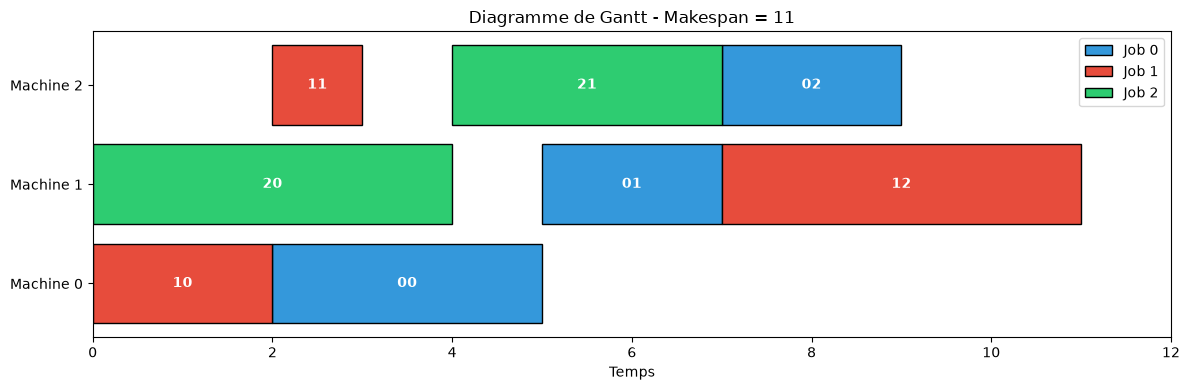

In [6]:
if ORTOOLS_OK and (status == cp_model.OPTIMAL or status == cp_model.FEASIBLE):
    # Affichage du schedule
    print("\n" + "=" * 60)
    print("SCHEDULE OPTIMAL")
    print("=" * 60)
    
    for job_name, operations in JOBS_DATA.items():
        print(f"\n{job_name}:")
        for task_id, (machine, duration) in enumerate(operations):
            start = solver.Value(all_tasks[(job_name, task_id)][0])
            end = solver.Value(all_tasks[(job_name, task_id)][1])
            print(f"  Op {task_id}: Machine {machine}, [{start}, {end}] (duree={duration})")
    
    # Visualisation en diagramme de Gantt
    fig, ax = plt.subplots(figsize=(12, 4))
    
    colors = ['#3498db', '#e74c3c', '#2ecc71']
    job_colors = {job_name: colors[i % len(colors)] 
                  for i, job_name in enumerate(JOBS_DATA.keys())}
    
    for job_name, operations in JOBS_DATA.items():
        for task_id, (machine, duration) in enumerate(operations):
            start = solver.Value(all_tasks[(job_name, task_id)][0])
            ax.barh(f'Machine {machine}', duration, left=start, 
                   color=job_colors[job_name], edgecolor='black',
                   label=f'{job_name}' if task_id == 0 else '')
            # Annotation
            ax.text(start + duration/2, f'Machine {machine}', 
                   f'{job_name[-1]}{task_id}', ha='center', va='center',
                   fontsize=10, fontweight='bold', color='white')
    
    ax.set_xlabel('Temps')
    ax.set_title(f'Diagramme de Gantt - Makespan = {solver.Value(makespan)}')
    ax.legend(loc='upper right')
    ax.set_xlim(0, solver.Value(makespan) + 1)
    plt.tight_layout()
    plt.show()

### Interpretation du Job Shop Schedule

**Sortie obtenue** : Un diagramme de Gantt montrant l'assignation des opérations aux machines.

| Job | Opérations | Contraintes de précédence |
|-----|------------|---------------------------|
| Job 0 | 3 opérations | Op0 -> Op1 -> Op2 |
| Job 1 | 3 opérations | Op0 -> Op1 -> Op2 |
| Job 2 | 2 opérations | Op0 -> Op1 |

**Points clés** :
1. Les contraintes **NoOverlap** assurent qu'une machine traite une opération a la fois
2. Les contraintes de **précédence** assurent l'ordre des opérations dans un job
3. Le solveur optimise le **makespan** (temps total de completion)

> **Comparaison avec PDDL** : Ce problème pourrait etre modelise en PDDL, mais CP-SAT est plus naturel et souvent plus efficace pour les problèmes d'ordonnancement purs.

***

## 4. Vehicle Routing Problem (VRP)

Le **Vehicle Routing Problem** est un problème classique de logistique : determiner les routes optimales d'une flotte de véhicules pour livrer des clients a partir d'un dépôt.

### 4.1 Definition du problème

**Données** :
- Un dépôt (position 0)
- $n$ clients (positions 1 a $n$)
- $k$ véhicules avec capacité $C$
- Matrice de distances $d_{ij}$
- Demandes $q_i$ pour chaque client

**Objectif** : Minimiser la distance totale parcourue par tous les véhicules

**Contraintes** :
- Chaque client est visite exactement une fois
- La capacité de chaque vehicule est respectee
- Chaque route commence et finit au dépôt

In [7]:
# OR-Tools a un module dedie au VRP
if ORTOOLS_OK:
    from ortools.constraint_solver import routing_enums_pb2
    from ortools.constraint_solver import pywrapcp
    
    # Donnees du probleme VRP
    # Positions: depot + 4 clients
    # Depot est a l'index 0
    
    def create_distance_matrix():
        """Cree une matrice de distances symetrique."""
        # Distances entre depot (0) et 4 clients (1-4)
        # Index: 0=Depot, 1=ClientA, 2=ClientB, 3=ClientC, 4=ClientD
        return [
            [0, 10, 15, 20, 25],   # Depuis depot
            [10, 0, 12, 18, 22],   # Depuis ClientA
            [15, 12, 0, 8, 16],    # Depuis ClientB
            [20, 18, 8, 0, 14],    # Depuis ClientC
            [25, 22, 16, 14, 0],   # Depuis ClientD
        ]
    
    def create_demand_vector():
        """Demande de chaque client (depot = 0)."""
        return [0, 3, 4, 2, 5]  # Depot, A, B, C, D
    
    # Parametres
    DISTANCE_MATRIX = create_distance_matrix()
    DEMANDS = create_demand_vector()
    NUM_VEHICLES = 2
    VEHICLE_CAPACITY = 8
    DEPOT = 0
    
    print("Probleme VRP")
    print("=" * 50)
    print(f"Clients: {len(DISTANCE_MATRIX) - 1}")
    print(f"Vehicules: {NUM_VEHICLES}")
    print(f"Capacite par vehicule: {VEHICLE_CAPACITY}")
    print(f"\nDemandes:")
    for i, d in enumerate(DEMANDS):
        if i > 0:
            print(f"  Client {i}: {d}")
    print(f"  Total demandes: {sum(DEMANDS)}")

Probleme VRP
Clients: 4
Vehicules: 2
Capacite par vehicule: 8

Demandes:
  Client 1: 3
  Client 2: 4
  Client 3: 2
  Client 4: 5
  Total demandes: 14


### Interpretation : Données du problème VRP

**Sortie obtenue** : Definition des données pour un problème de tournees de véhicules avec 4 clients et 2 véhicules.

| Élément | Valeur |
|---------|--------|
| **Clients** | 4 (A, B, C, D) |
| **Véhicules** | 2 (capacité 8 chacun) |
| **Demandes** | A=3, B=4, C=2, D=5 (total 14) |
| **Capacité totale** | 16 (suffisante pour 14) |

**Structure du problème** :
- Dépôt central (position 0)
- 4 clients avec demandes différentes
- 2 véhicules avec capacité limitee
- Matrice de distances symetrique

**Contrainte principale** : Un vehicule ne peut pas transporter plus de 8 unites de demande. Avec 14 unites totales, il faut au moins 2 véhicules (8+8=16 >= 14).

> **Note technique** : Le VRP est NP-difficile. Pour 4 clients, la solution est triviale, mais pour 100+ clients, les métaheuristiques (Guided Local Search) sont necessaires.

### 4.2 Resolution et affichage des routes

Maintenant que les données sont définies, nous configurons le **Routing Model** d'OR-Tools avec les callbacks de distance et de capacité, puis resolvons le problème.

In [8]:
if ORTOOLS_OK:
    # Creation du Routing Index Manager
    manager = pywrapcp.RoutingIndexManager(
        len(DISTANCE_MATRIX), 
        NUM_VEHICLES, 
        DEPOT
    )
    
    # Creation du Routing Model
    routing = pywrapcp.RoutingModel(manager)
    
    # Fonction de cout (distance)
    def distance_callback(from_index, to_index):
        """Retourne la distance entre deux noeuds."""
        from_node = manager.IndexToNode(from_index)
        to_node = manager.IndexToNode(to_index)
        return DISTANCE_MATRIX[from_node][to_node]
    
    transit_callback_index = routing.RegisterTransitCallback(distance_callback)
    routing.SetArcCostEvaluatorOfAllVehicles(transit_callback_index)
    
    # Contrainte de capacite
    def demand_callback(from_index):
        """Retourne la demande du noeud."""
        from_node = manager.IndexToNode(from_index)
        return DEMANDS[from_node]
    
    demand_callback_index = routing.RegisterUnaryTransitCallback(demand_callback)
    routing.AddDimensionWithVehicleCapacity(
        demand_callback_index,
        0,  # null capacity slack
        [VEHICLE_CAPACITY] * NUM_VEHICLES,  # capacites des vehicules
        True,  # start cumul to zero
        'Capacity'
    )
    
    # Heuristique de recherche
    search_parameters = pywrapcp.DefaultRoutingSearchParameters()
    search_parameters.first_solution_strategy = (
        routing_enums_pb2.FirstSolutionStrategy.PATH_CHEAPEST_ARC
    )
    search_parameters.local_search_metaheuristic = (
        routing_enums_pb2.LocalSearchMetaheuristic.GUIDED_LOCAL_SEARCH
    )
    search_parameters.time_limit.seconds = 5
    
    # Resolution
    print("Resolution VRP en cours...")
    solution = routing.SolveWithParameters(search_parameters)
    
    if solution:
        print(f"\nSolution trouvee !")
        print(f"Cout total (distance): {solution.ObjectiveValue()}")
        print("\nRoutes:")
        print("-" * 40)
        
        total_distance = 0
        total_load = 0
        
        for vehicle_id in range(NUM_VEHICLES):
            index = routing.Start(vehicle_id)
            plan_output = f'Vehicule {vehicle_id}: '
            route_distance = 0
            route_load = 0
            
            while not routing.IsEnd(index):
                node_index = manager.IndexToNode(index)
                route_load += DEMANDS[node_index]
                plan_output += f'{node_index} -> '
                previous_index = index
                index = solution.Value(routing.NextVar(index))
                route_distance += routing.GetArcCostForVehicle(
                    previous_index, index, vehicle_id
                )
            
            node_index = manager.IndexToNode(index)
            plan_output += f'{node_index}\n'
            plan_output += f'Distance: {route_distance}\n'
            plan_output += f'Charge: {route_load}/{VEHICLE_CAPACITY}\n'
            print(plan_output)
            
            total_distance += route_distance
            total_load += route_load
        
        print(f"\nResume:")
        print(f"  Distance totale: {total_distance}")
        print(f"  Charge totale livree: {total_load}")
    else:
        print("Pas de solution trouvee")

Resolution VRP en cours...



Solution trouvee !
Cout total (distance): 96

Routes:
----------------------------------------
Vehicule 0: 0 -> 3 -> 4 -> 0
Distance: 59
Charge: 7/8

Vehicule 1: 0 -> 1 -> 2 -> 0
Distance: 37
Charge: 7/8


Resume:
  Distance totale: 96
  Charge totale livree: 14


### Interpretation du VRP

**Sortie obtenue** : Routes optimales pour chaque vehicule avec distances et charges.

**Points clés** :
1. Le **Routing Model** d'OR-Tools est specialise pour les problèmes de tournees
2. Les **dimensions** (capacité, temps, distance) permettent d'ajouter des contraintes
3. Les **métaheuristiques** (Guided Local Search) ameliorent les solutions

> **Lien avec la planification** : Le VRP peut etre vu comme un problème de planification ou les "actions" sont les deplacements de véhicules, mais l'approche CP est plus naturelle.

***

## 5. Planning as SAT/CP

Il est possible d'encoder un problème de planification PDDL en SAT ou CP. Cette approche, appelee **planning-as-SAT**, peut etre très efficace.

### 5.1 Encodage séquentiel

L'idee est de créer des variables pour chaque fait a chaque pas de temps :

$$x_{p,t} = 1 \Leftrightarrow \text{le fait } p \text{ est vrai au temps } t$$

$$a_{a,t} = 1 \Leftrightarrow \text{l'action } a \text{ est executee au temps } t$$

**Contraintes** :
1. **Initial** : $x_{p,0} = 1$ pour les faits initiaux
2. **But** : $x_{g,T} = 1$ pour les buts (a l'horizon T)
3. **Préconditions** : $a_{a,t} \Rightarrow \bigwedge_{p \in pre(a)} x_{p,t}$
4. **Effets** : $a_{a,t} \Rightarrow \bigwedge_{e \in add(a)} x_{e,t+1} \land \bigwedge_{e \in del(a)} \neg x_{e,t+1}$
5. **Frame axioms** : Les faits non modifiés persistent

In [9]:
# Encodage sequentiel (SATPlan) : Planning as CP pour Blocks World
# On modelise le mini-probleme : deplacer le bloc A de la table vers B.
# Cet encodage suit la theorie de la cellule precedente (variables d'action a_{a,t},
# preconditions, effets, axiomes de cadre, exclusion mutuelle) -- l'objectif (minimiser
# le nombre d'actions = plan le plus court) rend l'optimisation de CP-SAT reellement visible.

if ORTOOLS_OK:
    model = cp_model.CpModel()

    HORIZON = 4  # Nombre max d'etapes
    T = range(HORIZON + 1)      # instants d'etat 0..HORIZON
    TA = range(HORIZON)          # transitions t -> t+1 (actions definies sur 0..HORIZON-1)

    # --- Faits d'etat x_{p,t} (booleens) ---
    def bv(nom):
        return {t: model.NewBoolVar(f"{nom}_{t}") for t in T}

    on_table_A = bv("on_table_A")
    on_table_B = bv("on_table_B")
    on_A_B     = bv("on_A_B")
    holding_A  = bv("holding_A")
    handempty  = bv("handempty")
    clear_A    = bv("clear_A")
    clear_B    = bv("clear_B")

    # --- Variables d'action a_{a,t} (booleens, definies sur les transitions) ---
    def bva(nom):
        return {t: model.NewBoolVar(f"{nom}_{t}") for t in TA}

    pickup_A   = bva("pickup_A")    # ramasser A depuis la table
    stack_A_B  = bva("stack_A_B")   # poser A sur B (depuis la main)

    # --- Etat initial (t = 0) ---
    model.Add(on_table_A[0] == 1)
    model.Add(on_table_B[0] == 1)
    model.Add(handempty[0] == 1)
    model.Add(clear_A[0] == 1)
    model.Add(clear_B[0] == 1)
    model.Add(on_A_B[0] == 0)
    model.Add(holding_A[0] == 0)

    # --- But : A sur B a l'horizon ---
    model.Add(on_A_B[HORIZON] == 1)

    # --- Exclusion mutuelle : au plus une action par pas de temps ---
    for t in TA:
        model.Add(pickup_A[t] + stack_A_B[t] <= 1)

    # --- Preconditions (action => preconditions vraies au temps t) ---
    for t in TA:
        model.Add(on_table_A[t] >= pickup_A[t])   # pickup_A : A sur table
        model.Add(clear_A[t]    >= pickup_A[t])   #           A degage
        model.Add(handempty[t]  >= pickup_A[t])   #           main vide
        model.Add(holding_A[t]  >= stack_A_B[t])  # stack_A_B : on tient A
        model.Add(clear_B[t]    >= stack_A_B[t])  #            B degage

    # --- Effets (action => faits ajoutes/supprimes au temps t+1) ---
    for t in TA:
        model.Add(holding_A[t + 1]  >= pickup_A[t])    # pickup_A : +holding_A
        model.Add(on_table_A[t + 1] <= 1 - pickup_A[t])#           -on_table_A
        model.Add(clear_A[t + 1]    <= 1 - pickup_A[t])#           -clear_A
        model.Add(handempty[t + 1]  <= 1 - pickup_A[t])#           -handempty
        model.Add(on_A_B[t + 1]     >= stack_A_B[t])   # stack_A_B: +on_A_B
        model.Add(holding_A[t + 1]  <= 1 - stack_A_B[t])#          -holding_A
        model.Add(handempty[t + 1]  >= stack_A_B[t])   #           +handempty
        model.Add(clear_B[t + 1]    <= 1 - stack_A_B[t])#          -clear_B

    # --- Axiomes de cadre (un fait persiste sauf si une action le modifie) ---
    for t in TA:
        model.Add(holding_A[t + 1]  >= holding_A[t] - stack_A_B[t])
        model.Add(holding_A[t + 1]  <= holding_A[t] + pickup_A[t])
        model.Add(handempty[t + 1]  >= handempty[t] - pickup_A[t])
        model.Add(handempty[t + 1]  <= handempty[t] + stack_A_B[t])
        model.Add(on_table_A[t + 1] >= on_table_A[t] - pickup_A[t])
        model.Add(on_table_A[t + 1] <= on_table_A[t])
        model.Add(on_A_B[t + 1]     >= on_A_B[t])
        model.Add(on_A_B[t + 1]     <= on_A_B[t] + stack_A_B[t])
        model.Add(clear_A[t + 1]    >= clear_A[t] - pickup_A[t])
        model.Add(clear_A[t + 1]    <= clear_A[t])
        model.Add(clear_B[t + 1]    >= clear_B[t] - stack_A_B[t])
        model.Add(clear_B[t + 1]    <= clear_B[t])

    # --- Localisation : A est a exactement un endroit a chaque instant ---
    for t in T:
        model.Add(on_table_A[t] + on_A_B[t] + holding_A[t] == 1)

    # --- Objectif : minimiser le nombre total d'actions (plan le plus court) ---
    total_actions = sum(pickup_A[t] for t in TA) + sum(stack_A_B[t] for t in TA)
    model.Minimize(total_actions)

    # --- Resolution ---
    solver = cp_model.CpSolver()
    status = solver.Solve(model)

    print("Planning as CP - Blocks World (encodage sequentiel SATPlan)")
    print("=" * 58)
    if status in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        print(f"Statut: {'OPTIMAL' if status == cp_model.OPTIMAL else 'FEASIBLE'}")
        print(f"Nombre d'actions: {solver.Value(total_actions)}"
              + (" (prouve minimal)" if status == cp_model.OPTIMAL else ""))
        print("\nPlan trouve (actions executees a chaque transition) :")
        for t in TA:
            if solver.Value(pickup_A[t]):
                print(f"  t={t}: pickup(A)    -- ramasser A sur la table")
            elif solver.Value(stack_A_B[t]):
                print(f"  t={t}: stack(A, B)  -- poser A sur B")
            else:
                print(f"  t={t}: (no-op)")
        print("\nEvolution des etats :")
        for t in T:
            locA = "Table" if solver.Value(on_table_A[t]) else ("B" if solver.Value(on_A_B[t]) else "Main")
            main = "Vide" if solver.Value(handempty[t]) else "Tient A"
            print(f"  t={t}: A sur {locA}, Main: {main}")
    else:
        print(f"Pas de solution (statut: {solver.StatusName(status)})")
        print("Note : augmenter HORIZON ou reviser les contraintes d'action.")
else:
    print("ortools non disponible : cellule d'encodage SATPlan sautee.")


Planning as CP - Blocks World (encodage sequentiel SATPlan)
Statut: OPTIMAL
Nombre d'actions: 2 (prouve minimal)

Plan trouve (actions executees a chaque transition) :
  t=0: (no-op)
  t=1: pickup(A)    -- ramasser A sur la table
  t=2: (no-op)
  t=3: stack(A, B)  -- poser A sur B

Evolution des etats :
  t=0: A sur Table, Main: Vide
  t=1: A sur Table, Main: Vide
  t=2: A sur Main, Main: Tient A
  t=3: A sur Main, Main: Tient A
  t=4: A sur B, Main: Vide


### Interpretation du Planning as CP

**Sortie obtenue** : CP-SAT (OR-Tools) retourne le statut **OPTIMAL** avec un plan de **2 actions** :
`t=1: pickup(A)` puis `t=3: stack(A, B)`. L'état evolue de maniere coherente -- A sur la table
(`t=0,1`), puis tenu en main (`t=2,3`), puis pose sur B (`t=4`) -- sans la contradiction d'un état
incoherent.

**Ce que demontre cet encodage** :

1. **Fidelite a la théorie de la cellule précédente.** L'encodage implemente exactement le schema
   séquentiel (SATPlan) : variables d'état $x_{p,t}$ et variables d'action $a_{a,t}$, préconditions
   ($a_{a,t} \Rightarrow pre(a)$), effets ($a_{a,t} \Rightarrow add(a)_{t+1} \land \lnot del(a)_{t+1}$),
   axiomes de cadre (persistance des faits non modifiés) et exclusion mutuelle (au plus une action
   par pas de temps). C'est ce qui rend l'evolution des états physiquement coherente.

2. **La capacité d'optimisation de CP-SAT est ici visible.** L'objectif `Minimize(total_actions)`
   pousse le solveur a trouver le **plan le plus court**. Le statut OPTIMAL (et non juste FEASIBLE)
   signifie que CP-SAT a **prouve** qu'aucun plan a 1 action (ni 0) ne peut atteindre le but : il
   faut au minimum ramasser A puis la poser sur B. C'est précisément la force d'un solveur de
   programmation par contraintes sur un problème combinatoire -- prouver l'optimalité, pas
   seulement trouver une solution faisable.

3. **Explosion combinatoire malgre la simplicite.** Même pour 2 blocs et un horizon de 4, le modèle
   mobilise déjà une trentaine de variables booléennes (faits x actions x temps) et des dizaines de
   contraintes. Le nombre de variables explose avec l'horizon, le nombre de blocs et le nombre
   d'actions possibles -- c'est pourquoi les planificateurs PDDL specialises (Fast Downward, etc.),
   qui exploitent des heuristiques dediees a la structure du domaine, restent nettement plus
   efficaces sur de grands problèmes de planification classique.

> **Quand preferer CP a PDDL ?** L'encodage CP devient avantageux des qu'on veut **combiner** la
> planification avec des contraintes difficiles a exprimer en PDDL pur : ressources limitees,
> fenêtres temporelles, coûts, contraintes d'ordonnancement. Le solveur CP peut alors optimiser
   un objectif global (minimiser le coût total, respecter un budget) tout en garantissant un plan
   executable -- ce qu'un planificateur PDDL standard ne fait pas nativement.

***

## 6. Comparaison CP vs PDDL

Cette section resume les différences et guide le choix entre CP et PDDL.

In [10]:
# Tableau comparatif detaille
comparison = {
    'Aspect': [
        'Paradigme',
        'Variables',
        'Contraintes',
        'Objectif',
        'Solution',
        'Problemes types',
        'Optimalite',
        'Scalabilite',
        'Expressivite',
        'Courbe apprentissage',
        'Outils',
    ],
    'PDDL (Planification)': [
        'Recherche dans espace d\'etats',
        'Predicats (faits booleens)',
        'Preconditions/effets des actions',
        'Minimiser longueur du plan',
        'Sequence d\'actions',
        'Blocks World, Logistics, Gripper',
        'Admissible (A* + LM-cut)',
        'Bonne avec heuristiques',
        'Actions, temps, objets',
        'Moyenne (syntaxe PDDL)',
        'Fast Downward, ENHSP',
    ],
    'CP (Contraintes)': [
        'Propagation + Recherche',
        'Entieres, booleennes, intervalles',
        'Lineaires, globales (AllDiff, etc.)',
        'Optimiser fonction objectif',
        'Affectation de variables',
        'Scheduling, VRP, Sudoku',
        'Exacte (CP-SAT)',
        'Tres bonne (propagation)',
        'Contraintes, ressources, temps',
        'Moyenne (API Python)',
        'OR-Tools, Gecode, Choco',
    ],
}

print("Comparaison CP vs PDDL")
print("=" * 80)
print(f"{'Aspect':<25} | {'PDDL':<25} | {'CP':<25}")
print("-" * 80)
for i in range(len(comparison['Aspect'])):
    print(f"{comparison['Aspect'][i]:<25} | {comparison['PDDL (Planification)'][i]:<25} | {comparison['CP (Contraintes)'][i]:<25}")
print("=" * 80)

Comparaison CP vs PDDL
Aspect                    | PDDL                      | CP                       
--------------------------------------------------------------------------------
Paradigme                 | Recherche dans espace d'etats | Propagation + Recherche  
Variables                 | Predicats (faits booleens) | Entieres, booleennes, intervalles
Contraintes               | Preconditions/effets des actions | Lineaires, globales (AllDiff, etc.)
Objectif                  | Minimiser longueur du plan | Optimiser fonction objectif
Solution                  | Sequence d'actions        | Affectation de variables 
Problemes types           | Blocks World, Logistics, Gripper | Scheduling, VRP, Sudoku  
Optimalite                | Admissible (A* + LM-cut)  | Exacte (CP-SAT)          
Scalabilite               | Bonne avec heuristiques   | Tres bonne (propagation) 
Expressivite              | Actions, temps, objets    | Contraintes, ressources, temps
Courbe apprentissage      | Moy

### 6.1 Analyse comparative detaillee

Le tableau ci-dessus compare les dimensions clés des deux paradigmes. Voyons maintenant un guide pratique pour choisir entre CP et PDDL selon le problème a résoudre.

In [11]:
# Guide de decision
decision_guide = """
GUIDE DE DECISION : PDDL ou CP ?
==================================

CHOISIR PDDL si :
------------------
1. Le probleme implique un AGENT qui EXECUTE des ACTIONS
2. Les actions ont des PRECONDITIONS et EFFETS clairs
3. On cherche une SEQUENCE d'actions (un plan)
4. Le domaine peut etre decrit avec des PREDICATS logiques
5. L'ordre des actions est crucial

Exemples typiques :
- Robot qui manipule des objets (Blocks World)
- Logistique avec chargement/dechargement
- Jeux avec coups autorises


CHOISIR CP (OR-Tools) si :
-------------------------
1. Le probleme est essentiellement COMBINATOIRE
2. On OPTIMISE une fonction objectif (temps, cout)
3. Les CONTRAINTES sont plus naturelles que les actions
4. Le probleme est STATIQUE (pas de sequence d'actions)
5. On a des RESSOURCES limitees (machines, vehicules)

Exemples typiques :
- Ordonnancement (Job Shop, Project Scheduling)
- Tournees de vehicules (VRP)
- Affectation (Sudoku, planning personnel)
- Decoupe, bin packing


HYBRIDE si :
-----------
1. Planification avec contraintes de ressources complexes
2. Planification temporelle (PDDL 2.1 + contraintes)
3. Utiliser unified-planning avec backend CP
"""

print(decision_guide)


GUIDE DE DECISION : PDDL ou CP ?

CHOISIR PDDL si :
------------------
1. Le probleme implique un AGENT qui EXECUTE des ACTIONS
2. Les actions ont des PRECONDITIONS et EFFETS clairs
3. On cherche une SEQUENCE d'actions (un plan)
4. Le domaine peut etre decrit avec des PREDICATS logiques
5. L'ordre des actions est crucial

Exemples typiques :
- Robot qui manipule des objets (Blocks World)
- Logistique avec chargement/dechargement
- Jeux avec coups autorises


CHOISIR CP (OR-Tools) si :
-------------------------
1. Le probleme est essentiellement COMBINATOIRE
2. On OPTIMISE une fonction objectif (temps, cout)
3. Les CONTRAINTES sont plus naturelles que les actions
4. Le probleme est STATIQUE (pas de sequence d'actions)
5. On a des RESSOURCES limitees (machines, vehicules)

Exemples typiques :
- Ordonnancement (Job Shop, Project Scheduling)
- Tournees de vehicules (VRP)
- Affectation (Sudoku, planning personnel)
- Decoupe, bin packing


HYBRIDE si :
-----------
1. Planification avec cont

***

## 7. Resume et points clés

### 7.1 Concepts appris

| Concept | Description |
|---------|-------------|
| **CP-SAT** | Solveur de contraintes Google OR-Tools |
| **Variables d'intervalle** | Modèles avec debut, durée, fin |
| **NoOverlap** | Contrainte de non-chevauchement |
| **Makespan** | Temps total de completion |
| **Routing Model** | API specialisee pour le VRP |
| **Planning-as-SAT** | Encodage de planification en SAT/CP |

### 7.2 Points clés a retenir

1. **CP vs PDDL** : Deux paradigmes complémentaires
   - PDDL pour les sequences d'actions avec préconditions/effets
   - CP pour l'optimisation combinatoire avec contraintes

2. **OR-Tools CP-SAT** est excellent pour :
   - Scheduling (Job Shop, Project)
   - Routing (VRP, TSP)
   - Problèmes d'affectation

3. **Choisir le bon outil** :
   - Si le problème est "que faire ?" -> PDDL
   - Si le problème est "comment optimiser ?" -> CP

4. **Integration possible** :
   - unified-planning peut utiliser des solveurs CP
   - Les deux approches peuvent etre combinees

## Resume et perspectives

Ce notebook a presente **Google OR-Tools** et son solveur **CP-SAT** comme une approche complémentaire a la planification PDDL classique. Nous avons modelise et resolu deux problèmes fondamentaux d'optimisation combinatoire : le **Job Shop Scheduling** (ordonnancement d'opérations sur des machines avec contraintes de précédence et contraintes NoOverlap) et le **Vehicle Routing Problem** (optimisation de tournees de véhicules avec contraintes de capacité). L'encodage planning-as-SAT a illustre comment un problème de planification Blocks World peut etre traduit en variables et contraintes CP, bien que cette approche soit généralement moins efficace que les solveurs PDDL specialises pour les problèmes d'actions séquentielles.

La programmation par contraintes excelle dans les problèmes ou l'objectif est d'optimiser une fonction objectif (minimiser le makespan, minimiser la distance totale) plutot que de trouver une sequence d'actions. Les variables d'intervalle, les contraintes NoOverlap et Cumulative, et le moteur de propagation de CP-SAT permettent de résoudre optimalement des instances de taille industrielle en quelques millisecondes. A l'inverse, PDDL reste superieur quand le problème implique un agent qui execute des actions avec préconditions et effets clairs. Le guide de decision presente dans ce notebook offre un cadre systématique pour choisir entre les deux paradigmes selon la nature du problème.

Le notebook suivant, [Planners-08-Temporal-Python](Planners-08-Temporal-Python.ipynb), explore la **planification temporelle** avec PDDL 2.1, qui introduit des durées explicites et le parallélisme d'actions -- un pont naturel entre la planification classique et les problèmes d'ordonnancement traites ici avec CP-SAT.

### 7.3 Prochaines étapes

Dans le notebook **Planners-08-Temporal-Python**, nous explorerons :
- PDDL 2.1 avec durées et parallellisme
- Planification temporelle
- Integration avec les contraintes de temps

***

## Ressources

- [OR-Tools Documentation](https://developers.google.com/optimization)
- [CP-SAT Primer](https://github.com/google/or-tools/blob/stable/ortools/sat/docs/README.md)
- [Job Shop Scheduling Example](https://developers.google.com/optimization/scheduling/job_shop)
- [VRP Documentation](https://developers.google.com/optimization/routing)

***

**Notebook suivant** : [Planners-08-Temporal-Python](Planners-08-Temporal-Python.ipynb)

***

## Exemple guide : Resolution du problème des N-Reines avec CP-SAT

Pour illustrer la puissance de la programmation par contraintes sur un problème classique, resolvons le **problème des N-Reines** : placer $N$ reines sur un echiquier $N \times N$ de sorte qu'aucune ne menace une autre.

Ce problème est un excellent cas d'école car :
- **Toutes les reines doivent etre sur des lignes, colonnes et diagonales différentes** — naturellement exprimable avec la contrainte `AllDifferent`
- **Pas de "sequence d'actions"** — c'est un problème d'affectation, pas de planification PDDL
- **Explosion combinatoire** — pour $N=8$, il existe $4\,426\,165\,368$ placements possibles, mais seulement **92 solutions**

Probleme des 8-Reines
Nombre de solutions : 92
Premiere solution   : [4, 7, 3, 0, 2, 5, 1, 6]


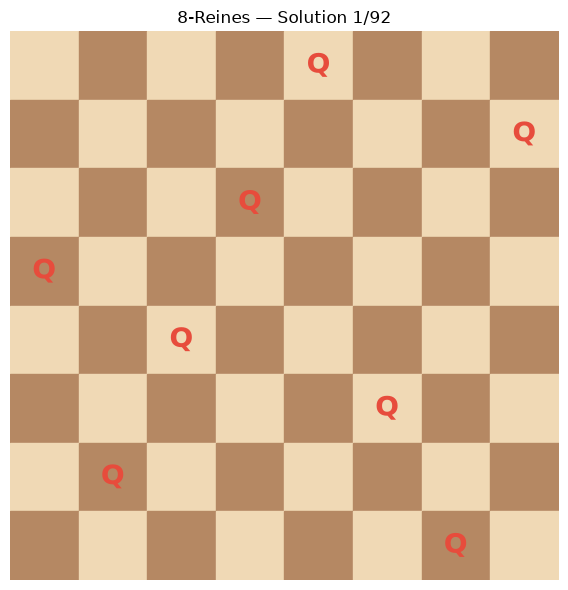


Verification de la solution [4, 7, 3, 0, 2, 5, 1, 6] :
  Colonnes toutes differentes : True
  Diagonales \ toutes differentes : True
  Diagonales / toutes differentes : True
  Solution valide : True

--- Performance CP-SAT ---
  N= 4 :      2 solutions en 0.0017s
  N= 6 :      4 solutions en 0.0045s
  N= 8 :     92 solutions en 0.0382s


  N=10 :    724 solutions en 0.4372s


  N=12 :  14200 solutions en 9.4532s


In [12]:
if ORTOOLS_OK:
    from ortools.sat.python import cp_model
    
    def solve_n_queens(n=8):
        """Resout le probleme des N-Reines avec CP-SAT et retourne toutes les solutions."""
        model = cp_model.CpModel()
        
        # Variable : queens[i] = colonne de la reine sur la ligne i
        # Domaine : [0, n-1] (les n colonnes possibles)
        queens = [model.NewIntVar(0, n - 1, f'q{i}') for i in range(n)]
        
        # Contrainte 1 : toutes les reines sur des colonnes differentes
        model.AddAllDifferent(queens)
        
        # Contrainte 2 : pas de conflit sur les diagonales \ (i - queens[i] tous differents)
        diag1 = [model.NewIntVar(-n + 1, n - 1, f'd1_{i}') for i in range(n)]
        for i in range(n):
            model.Add(diag1[i] == i - queens[i])
        model.AddAllDifferent(diag1)
        
        # Contrainte 3 : pas de conflit sur les diagonales / (i + queens[i] tous differents)
        diag2 = [model.NewIntVar(0, 2 * n - 2, f'd2_{i}') for i in range(n)]
        for i in range(n):
            model.Add(diag2[i] == i + queens[i])
        model.AddAllDifferent(diag2)
        
        # Resolution : trouver toutes les solutions
        solver = cp_model.CpSolver()
        solutions = []
        
        class SolutionCollector(cp_model.CpSolverSolutionCallback):
            def __init__(self, queens):
                super().__init__()
                self._queens = queens
                self._solutions = []
            
            def on_solution_callback(self):
                self._solutions.append([self.Value(q) for q in self._queens])
            
            def get_solutions(self):
                return self._solutions
        
        collector = SolutionCollector(queens)
        solver.SearchForAllSolutions(model, collector)
        solutions = collector.get_solutions()
        
        return solutions
    
    # Resolution pour N=8
    solutions_8 = solve_n_queens(8)
    print(f"Probleme des 8-Reines")
    print(f"=" * 40)
    print(f"Nombre de solutions : {len(solutions_8)}")
    print(f"Premiere solution   : {solutions_8[0]}")
    
    # Visualisation de la premiere solution
    sol = solutions_8[0]
    n = len(sol)
    fig, ax = plt.subplots(figsize=(6, 6))
    
    # Echiquier
    for i in range(n):
        for j in range(n):
            color = '#f0d9b5' if (i + j) % 2 == 0 else '#b58863'
            ax.add_patch(plt.Rectangle((j, n - 1 - i), 1, 1, color=color))
    
    # Reines
    for row, col in enumerate(sol):
        ax.text(col + 0.5, n - 1 - row + 0.5, 'Q', ha='center', va='center',
                fontsize=20, fontweight='bold', color='#e74c3c')
    
    ax.set_xlim(0, n)
    ax.set_ylim(0, n)
    ax.set_aspect('equal')
    ax.set_title(f'8-Reines — Solution 1/92')
    ax.axis('off')
    plt.tight_layout()
    plt.show()
    
    # Verification de la solution
    print(f"\nVerification de la solution {sol} :")
    cols_ok = len(set(sol)) == n
    diag1_ok = len(set(i - sol[i] for i in range(n))) == n
    diag2_ok = len(set(i + sol[i] for i in range(n))) == n
    print(f"  Colonnes toutes differentes : {cols_ok}")
    print(f"  Diagonales \\ toutes differentes : {diag1_ok}")
    print(f"  Diagonales / toutes differentes : {diag2_ok}")
    print(f"  Solution valide : {cols_ok and diag1_ok and diag2_ok}")
    
    # Performance pour differents N
    print(f"\n--- Performance CP-SAT ---")
    for size in [4, 6, 8, 10, 12]:
        import time
        t0 = time.time()
        sols = solve_n_queens(size)
        elapsed = time.time() - t0
        print(f"  N={size:2d} : {len(sols):6d} solutions en {elapsed:.4f}s")

### Interpretation : N-Reines avec CP-SAT

**Résultats** (mesures sur cette machine) :

| N | Solutions | Temps |
|---|-----------|-------|
| 4 | 2 | runtime *machine-dep* |
| 6 | 4 | runtime *machine-dep* |
| 8 | 92 | runtime *machine-dep* |
| 10 | 724 | runtime *machine-dep* |
| 12 | 14\,200 | runtime *machine-dep* |

> **Lecture** : le nombre de solutions explose (92 -> 724 -> 14\,200, structurel invariant) et le temps
> de recherche croit de maniere super-exponentielle (runtime *machine-dep* croissant en N ; depend du runtime OR-Tools + charge système + taille instance N).
> N=12 reste resolu en un runtime *machine-dep* *parce que* la
> propagation de CP-SAT elague massivement l'arbre ; un backtracking naïf serait
> infiniment plus lent.

**Pourquoi CP excelle ici** :
1. **3 contraintes `AddAllDifferent`** suffisent pour exprimer tout le problème — pas besoin d'enumerer les conflits pair a pair
2. La **propagation de contraintes** elimine les domaines impossibles avant même de chercher, reduisant drastiquement l'arbre de recherche
3. Le problème est purement **combinatoire** (affectation de colonnes aux lignes) — exactement le domaine de la CP

**Pourquoi PDDL serait inefficace** : le problème des N-Reines ne se decompose pas naturellement en "actions avec préconditions/effets". Il faudrait encodurer chaque placement comme une action, et le plan serait une sequence artificielle — la CP est l'outil naturel.

> **Lien pédagogique** : cet exemple illustre la conclusion du guide de decision — quand le problème est "trouver une affectation valide" plutot que "trouver une sequence d'actions", la programmation par contraintes est le paradigme adapte.

## Exemple guide : Optimisation d'un Emploi du Temps avec CP-SAT (crédité #27385 — GaetanPsx)

> Résolution originale : **GaetanPsx** (avec MaloD25), PR étudiante [#27385](https://github.com/jsboige/CoursIA/pull/27385). Reprise telle quelle ; seule la mise en forme est harmonisée avec les sections voisines.

Problème réaliste d'ordonnancement : planifier quatre cours (durées, professeurs, effectifs) dans deux salles sur la journée 8h-18h, sans qu'un professeur ou une salle n'ait deux cours en même temps, chaque cours dans une salle assez grande, et avec le **moins de trous possible** dans les emplois du temps des professeurs.

**Approche** : chaque couple (cours, salle) reçoit un **intervalle optionnel** (`NewOptionalIntervalVar`) qui n'existe que si le cours a lieu dans cette salle ; `AddExactlyOne` choisit la salle, et une salle trop petite est écartée d'office (`dans[c, s] == 0`). `AddNoOverlap` sérialise alors les cours salle par salle, et professeur par professeur (sur les intervalles obligatoires). Les trous d'un professeur sont calculés par min/max de ses débuts et fins (`AddMinEquality` / `AddMaxEquality`), et l'objectif combine les deux critères par pondération : éliminer les trous d'abord (poids 100), finir tôt ensuite.

In [13]:
from ortools.sat.python import cp_model

cours = {
    'Math': {'duree': 2, 'prof': 'A', 'eleves': 30},
    'Physique': {'duree': 2, 'prof': 'B', 'eleves': 25},
    'Info': {'duree': 3, 'prof': 'A', 'eleves': 20},
    'Chimie': {'duree': 2, 'prof': 'C', 'eleves': 25},
}
salles = {
    'S1': {'capacite': 30},
    'S2': {'capacite': 40},
}
creneaux = list(range(8, 18))  # 8h-18h
DEBUT, FIN = creneaux[0], creneaux[-1] + 1  # journee [8h, 18h]

model = cp_model.CpModel()
start, end, itv, dans = {}, {}, {}, {}
par_salle = {s: [] for s in salles}
par_prof = {}

for c, info in cours.items():
    d = info['duree']
    start[c] = model.NewIntVar(DEBUT, FIN - d, f'start_{c}')
    end[c] = model.NewIntVar(DEBUT + d, FIN, f'end_{c}')
    itv[c] = model.NewIntervalVar(start[c], d, end[c], f'itv_{c}')
    par_prof.setdefault(info['prof'], []).append(c)

    for s in salles:
        # dans[c, s] = 1 si le cours c a lieu dans la salle s
        dans[c, s] = model.NewBoolVar(f'{c}_{s}')
        if salles[s]['capacite'] < info['eleves']:
            model.Add(dans[c, s] == 0)  # salle trop petite
        # intervalle qui n'existe que si le cours est dans cette salle
        par_salle[s].append(model.NewOptionalIntervalVar(start[c], d, end[c], dans[c, s], f'itv_{c}_{s}'))
    model.AddExactlyOne(dans[c, s] for s in salles)

for s in salles:
    model.AddNoOverlap(par_salle[s])                    # une salle = un cours a la fois
for p, cs in par_prof.items():
    model.AddNoOverlap([itv[c] for c in cs])            # un prof = un cours a la fois
model.AddCumulative(itv.values(), [1] * len(cours), len(salles))  # max 2 cours en parallele

# Trous d'un prof = (fin du dernier cours - debut du premier) - temps d'enseignement
trous = []
for p, cs in par_prof.items():
    first = model.NewIntVar(DEBUT, FIN, f'first_{p}')
    last = model.NewIntVar(DEBUT, FIN, f'last_{p}')
    model.AddMinEquality(first, [start[c] for c in cs])
    model.AddMaxEquality(last, [end[c] for c in cs])
    trous.append(last - first - sum(cours[c]['duree'] for c in cs))

# 2 criteres : d'abord pas de trous, ensuite finir le plus tot possible
fin_journee = model.NewIntVar(DEBUT, FIN, 'fin_journee')
model.AddMaxEquality(fin_journee, list(end.values()))
model.Minimize(100 * sum(trous) + fin_journee)

solver = cp_model.CpSolver()
status = solver.Solve(model)
print("Statut :", solver.StatusName(status))
for c in sorted(cours, key=lambda c: solver.Value(start[c])):
    salle = next(s for s in salles if solver.Value(dans[c, s]))
    print(f"{c:<9} prof {cours[c]['prof']}  {salle}  "
          f"{solver.Value(start[c])}h-{solver.Value(end[c])}h")
print("Trous :", sum(solver.Value(t) for t in trous), "h")

Statut : OPTIMAL
Info      prof A  S2  8h-11h
Chimie    prof C  S1  8h-10h
Physique  prof B  S1  10h-12h
Math      prof A  S2  11h-13h
Trous : 0 h


### Exercice 1 : Emploi du temps avec indisponibilités

L'exemple guide suppose salles et professeurs disponibles toute la journée. Étendez ce modèle avec deux **indisponibilités** : la salle S1 est en maintenance de **8h à 10h**, et le professeur B est absent de **16h à 18h**. Objectif inchangé : minimiser la fin de journée tout en respectant les indisponibilités.

**Indices** :
- `#Étape 1` : Reprendre les variables de l'exemple guide (`start`, `end`, `itv`, `dans`, intervalles optionnels par salle)
- `#Étape 2` : L'indisponibilité du prof B est un **intervalle fixe** `[16, 18]` ajouté à sa liste `AddNoOverlap` — pas besoin de nouvelle variable
- `#Étape 3` : Celle de la salle S1 doit agir **seulement si le cours est en S1** : pour chaque cours, deux booléens (« fin avant 8h » / « début après 10h ») liés par `AddBoolOr`, chacun `OnlyEnforceIf(dans[c, 'S1'])`
- `#Étape 4` : Minimiser la fin de journée, afficher l'emploi du temps et vérifier qu'aucun cours ne chevauche un créneau interdit

In [14]:
if ORTOOLS_OK:
    # TODO etudiant: reprendre les donnees et variables de l'exemple guide,
    # puis ajouter l'indisponibilite de S1 (8h-10h) et celle du prof B (16h-18h).
    # Indice: intervalle fixe dans le NoOverlap du prof ; AddBoolOr + OnlyEnforceIf pour la salle.
    print("Exercice a completer")

Exercice a completer


### Exercice 2 : Variante Job Shop

Etendez le problème Job Shop de la section 3 en ajoutant **un 4e job** avec 3 opérations.

**Objectif** : Completer le dataset et re-résoudre avec CP-SAT.

**Indices** :
- `# Étape 1` : Ajouter un job `j3 = [(machine, duree), ...]` au dictionnaire `jobs_data`
- `# Étape 2` : Re-créer le modèle CP-SAT avec `NewIntervalVar` et `AddNoOverlap`
- `# Étape 3` : Minimiser le makespan
- `# Étape 4` : Afficher le makespan et comparer avec le résultat a 3 jobs

In [15]:
if ORTOOLS_OK:
    from ortools.sat.python import cp_model

    # TODO etudiant: ajoutez un 4e job au dataset Fisher & Thompson
    jobs_data_extended = None  # TODO etudiant

    print(f"Jobs etendus: {jobs_data_extended}")
    print("Exercice a completer")


Jobs etendus: None
Exercice a completer


### Exercice 3 : VRP avec flotte heterogene

Le VRP de la section 4 impose une capacité **uniforme** (`VEHICLE_CAPACITY = 8` pour les 2 véhicules). Etendez ce modèle avec une flotte **heterogene** : donnez a chaque vehicule une capacité différente et ajoutez un 3e vehicule.

**Objectif** : Modifier l'appel a `AddDimensionWithVehicleCapacity` pour passer un tableau de capacites distinctes (`vehicle_capacities` au lieu de `[VEHICLE_CAPACITY]*NUM_VEHICLES`).

**Indices** :
- `# Étape 1` : Reutiliser les demandes de la section 4 (`DEMANDS = [0, 3, 4, 2, 5]`)
- `# Étape 2` : Définir `vehicle_capacities = [8, 6, 5]` (3 véhicules, capacites différentes)
- `# Étape 3` : Passer ce tableau a `routing.AddDimensionWithVehicleCapacity(demand_callback_index, 0, vehicle_capacities, True, 'Capacity')`
- `# Étape 4` : Afficher la charge de chaque vehicule et vérifier qu'aucune ne depasse sa capacité

In [16]:
if ORTOOLS_OK:
    from ortools.constraint_solver import routing_enums_pb2
    from ortools.constraint_solver import pywrapcp

    # TODO etudiant: ajoutez des demandes et capacites au VRP
    demands = None  # TODO etudiant
    vehicle_capacities = None  # TODO etudiant

    print(f"Demandes: {demands}, Capacites: {vehicle_capacities}")
    print("Exercice a completer")


Demandes: None, Capacites: None
Exercice a completer
